# Phase 1: Data selection and audit (ACN-Data, Caltech + JPL)

Goal: forecast the number of EVs plugged in at a given time. The raw data is one row per charging session, so the notebook:

1. Loads and flattens the sessions
2. Cleans them
3. Audits data quality (missingness, outliers, duplicates, plots)
4. Builds the target (occupancy on a 15-min grid)
5. Builds leak-free features and saves them

## 0. Setup

In [1]:
import glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "./acn_dataset"
OUT_DIR = "./outputs"
FREQ = "15min"             # time grid for the occupancy series
HORIZON_STEPS = 4          # 4 x 15 min = predict 1 hour ahead
STUCK_HOURS = 72           # "very long" threshold used together with near-zero energy
LOCAL_TZ = "America/Los_Angeles"

os.makedirs(f"{OUT_DIR}/tables", exist_ok=True)
os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)
pd.set_option("display.max_columns", 50)

## 1. Load data

Each row gets its `site` from the filename.

In [37]:
def load_file(path):
    with open(path) as f:
        items = json.load(f)
    return pd.DataFrame(items)

def load_all(data_dir):
    frames = []
    for p in sorted(glob.glob(os.path.join(data_dir, "acn_*.json"))):
        df = load_file(p)
        df["site"] = "caltech" if "caltech" in os.path.basename(p) else "jpl"
        df["source_file"] = os.path.basename(p)
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

raw = load_all(DATA_DIR)
print(raw.shape)
caltech = raw[raw["site"] == "caltech"]


raw.head(3)

(44989, 15)


,_id,userInputs,sessionID,stationID,spaceID,siteID,clusterID,connectionTime,disconnectTime,kWhDelivered,doneChargingTime,timezone,userID,site,source_file
0,5c3fda9df9af8b0d99c6fd61,"[{'userID': 1616, 'milesRequested': 20, 'WhPer...",2_39_130_31_2019-01-01 05:28:33.527740,2-39-130-31,CA-306,0002,0039,2018-12-31 21:28:34-08:00,2018-12-31 22:03:12-08:00,3.250,2018-12-31 22:03:06-08:00,America/Los_Angeles,000001616,caltech,acn_caltech_2019_01.json
1,5c412c1df9af8b12cb56c27c,None,2_39_138_566_2019-01-01 17:41:44.784919,2-39-138-566,CA-512,0002,0039,2019-01-01 09:41:45-08:00,2019-01-01 10:39:21-08:00,0.900,2019-01-01 10:40:21-08:00,America/Los_Angeles,None,caltech,acn_caltech_2019_01.json
2,5c412c1df9af8b12cb56c27d,"[{'userID': 558, 'milesRequested': 80, 'WhPerM...",2_39_79_379_2019-01-01 18:09:16.991864,2-39-79-379,CA-327,0002,0039,2019-01-01 10:09:17-08:00,2019-01-01 18:39:32-08:00,12.534,2019-01-01 12:16:10-08:00,America/Los_Angeles,000000558,caltech,acn_caltech_2019_01.json


## 2. Flatten `userInputs` and parse timestamps

`userInputs` is a list of dicts (a user can edit it several times). We keep the **last** entry and count the edits. Timestamps come in mixed formats (`-08:00` offsets and `GMT` strings), so everything is parsed to UTC.

In [3]:
def flatten_user_inputs(df):
    n_edits = df["userInputs"].apply(lambda x: len(x) if isinstance(x, list) else 0)
    last = df["userInputs"].apply(lambda x: x[-1] if isinstance(x, list) and len(x) else {})
    ui = pd.DataFrame(last.tolist(), index=df.index).add_prefix("ui_")
    for c in ["ui_kWhRequested", "ui_minutesAvailable", "ui_milesRequested",
              "ui_WhPerMile", "ui_requestedDeparture", "ui_modifiedAt"]:
        if c not in ui:
            ui[c] = np.nan
    out = df.drop(columns=["userInputs"]).join(ui)
    out["n_userinput_edits"] = n_edits
    return out

def parse_times(df):
    for c in ["connectionTime", "disconnectTime", "doneChargingTime",
              "ui_requestedDeparture", "ui_modifiedAt"]:
        if c in df:
            df[c] = pd.to_datetime(df[c], utc=True, errors="coerce")
    return df

df = parse_times(flatten_user_inputs(raw))
df[["connectionTime", "disconnectTime", "doneChargingTime", "kWhDelivered", "ui_kWhRequested"]].head()

,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,ui_kWhRequested
0,2019-01-01 05:28:34+00:00,2019-01-01 06:03:12+00:00,2019-01-01 06:03:06+00:00,3.250,8.00
1,2019-01-01 17:41:45+00:00,2019-01-01 18:39:21+00:00,2019-01-01 18:40:21+00:00,0.900,NaN
2,2019-01-01 18:09:17+00:00,2019-01-02 02:39:32+00:00,2019-01-01 20:16:10+00:00,12.534,17.76
3,2019-01-01 18:39:25+00:00,2019-01-01 19:18:49+00:00,2019-01-01 19:19:47+00:00,0.883,NaN
4,2019-01-01 19:18:53+00:00,2019-01-01 20:14:07+00:00,2019-01-01 19:59:08+00:00,0.879,NaN


## 3. Quality flags

Flags are computed first and counted, then only impossible rows are removed. Long stays are **legitimate** (some cars stay for days) and they affect the occupancy target, so they are only flagged.

In [24]:
def add_flags(df):
    df["duration_h"] = (df["disconnectTime"] - df["connectionTime"]).dt.total_seconds() / 3600
    df["has_userinputs"] = df["ui_kWhRequested"].notna()
    df["flag_missing_times"] = df["connectionTime"].isna() | df["disconnectTime"].isna()
    df["flag_neg_duration"] = df["duration_h"] <= 0
    df["flag_long_duration"] = df["duration_h"] > df["duration_h"].quantile(0.999)   # flag only
    df["flag_kwh_outlier"] = (df["kWhDelivered"] < 0)
    df["flag_done_after_disc"] = df["doneChargingTime"] > df["disconnectTime"]
    df["flag_stuck_suspect"] = (df["duration_h"] > STUCK_HOURS) & (df["kWhDelivered"] < 0.5)
    return df

df = add_flags(df)
flag_cols = [c for c in df if c.startswith("flag_")]
print("duplicate sessionIDs:", df.duplicated("sessionID").sum())
df[flag_cols].sum().to_frame("rows_flagged")

duplicate sessionIDs: 0


,rows_flagged
flag_missing_times,0
flag_neg_duration,0
flag_long_duration,45
flag_kwh_outlier,0
flag_done_after_disc,3549
flag_stuck_suspect,0


Duration percentiles:

In [5]:
df["duration_h"].describe(percentiles=[.5, .9, .99, .999]).round(2).to_frame("duration_h")

,duration_h
count,44989.00
mean,6.30
std,4.33
min,0.03
50%,6.35
90%,10.25
99%,14.05
99.9%,39.08
max,214.32


## 4. Cleaning

- Drop duplicate `sessionID`s (monthly files can overlap)
- Drop rows with missing timestamps or non-positive duration (impossible)
- Drop suspected stuck sessions (very long **and** almost no energy)
- Set implausible `kWhDelivered` to NaN but **keep** the session (the car was still there)

In [6]:
def clean(df):
    n0 = len(df)
    df = df.drop_duplicates(subset="sessionID", keep="first")
    df = df[~df["flag_missing_times"] & ~df["flag_neg_duration"]].copy()
    df.loc[df["flag_kwh_outlier"], "kWhDelivered"] = np.nan
    df = df[~df["flag_stuck_suspect"]].copy()
    print(f"rows: {n0} -> {len(df)} ({n0 - len(df)} removed)")
    return df

clean_df = clean(df)

rows: 44989 -> 44989 (0 removed)


## 5. Audit tables

In [7]:
missing = (df.drop(columns=["_id"], errors="ignore").isna().mean().mul(100).round(2)
           .sort_values(ascending=False).to_frame("pct_missing"))
missing.to_csv(f"{OUT_DIR}/tables/missingness.csv")
missing

,pct_missing
ui_WhPerMile,6.94
ui_paymentRequired,6.94
ui_minutesAvailable,6.94
ui_requestedDeparture,6.94
ui_milesRequested,6.94
ui_userID,6.94
ui_kWhRequested,6.94
userID,6.94
ui_modifiedAt,6.94
doneChargingTime,6.27


In [8]:
num_cols = [c for c in ["kWhDelivered", "duration_h", "ui_milesRequested",
                        "ui_WhPerMile", "ui_minutesAvailable", "ui_kWhRequested"] if c in df]
stats = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3)
stats.to_csv(f"{OUT_DIR}/tables/summary_stats.csv")
stats

,count,mean,std,min,1%,25%,50%,75%,99%,max
kWhDelivered,44989.0,12.628,11.047,0.501,0.743,5.373,9.570,15.640,50.861,108.797
duration_h,44989.0,6.299,4.333,0.034,0.377,3.063,6.353,9.253,14.051,214.322
ui_milesRequested,41866.0,76.205,63.241,0.000,10.000,30.000,50.000,100.000,290.000,775.000
ui_WhPerMile,41866.0,361.404,102.818,50.000,200.000,288.000,350.000,400.000,600.000,2000.000
ui_minutesAvailable,41866.0,355.095,199.140,5.000,58.650,188.000,360.000,492.000,764.000,10062.000
ui_kWhRequested,41866.0,25.739,21.281,0.000,4.250,12.000,19.980,32.500,104.000,215.320


In [9]:
per_site_year = (clean_df.assign(year=clean_df["connectionTime"].dt.year)
                 .groupby(["site", "year"]).size().unstack(0).fillna(0).astype(int))
per_site_year.to_csv(f"{OUT_DIR}/tables/sessions_per_site_year.csv")
print("share of sessions with userInputs: %.1f%%" % (100 * df["has_userinputs"].mean()))
per_site_year

share of sessions with userInputs: 93.1%


site,caltech,jpl
year,,
2019,10616,17411
2020,2472,5576
2021,3038,5876


In [10]:
clean_df.head(5).T.to_csv(f"{OUT_DIR}/tables/example_rows.csv")
clean_df.head(5).T

,0,1,2,3,4
_id,5c3fda9df9af8b0d99c6fd61,5c412c1df9af8b12cb56c27c,5c412c1df9af8b12cb56c27d,5c412c1df9af8b12cb56c27e,5c412c1df9af8b12cb56c27f
sessionID,2_39_130_31_2019-01-01 05:28:33.527740,2_39_138_566_2019-01-01 17:41:44.784919,2_39_79_379_2019-01-01 18:09:16.991864,2_39_138_566_2019-01-01 18:39:24.566872,2_39_138_566_2019-01-01 19:18:52.843645
stationID,2-39-130-31,2-39-138-566,2-39-79-379,2-39-138-566,2-39-138-566
spaceID,CA-306,CA-512,CA-327,CA-512,CA-512
siteID,0002,0002,0002,0002,0002
clusterID,0039,0039,0039,0039,0039
connectionTime,2019-01-01 05:28:34+00:00,2019-01-01 17:41:45+00:00,2019-01-01 18:09:17+00:00,2019-01-01 18:39:25+00:00,2019-01-01 19:18:53+00:00
disconnectTime,2019-01-01 06:03:12+00:00,2019-01-01 18:39:21+00:00,2019-01-02 02:39:32+00:00,2019-01-01 19:18:49+00:00,2019-01-01 20:14:07+00:00
kWhDelivered,3.25,0.9,12.534,0.883,0.879
doneChargingTime,2019-01-01 06:03:06+00:00,2019-01-01 18:40:21+00:00,2019-01-01 20:16:10+00:00,2019-01-01 19:19:47+00:00,2019-01-01 19:59:08+00:00


## 6. Distribution plots and correlation

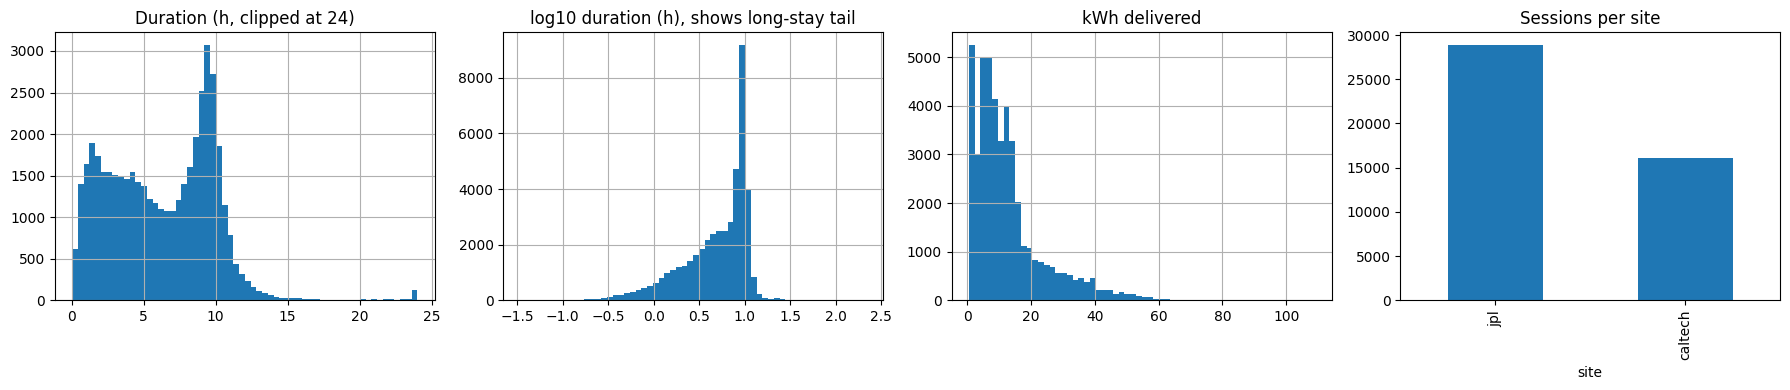

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
clean_df["duration_h"].clip(upper=24).hist(bins=60, ax=ax[0]); ax[0].set_title("Duration (h, clipped at 24)")
np.log10(clean_df["duration_h"]).hist(bins=60, ax=ax[1]); ax[1].set_title("log10 duration (h), shows long-stay tail")
clean_df["kWhDelivered"].hist(bins=60, ax=ax[2]); ax[2].set_title("kWh delivered")
clean_df["site"].value_counts().plot.bar(ax=ax[3]); ax[3].set_title("Sessions per site")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/distributions.png", dpi=150); plt.show()

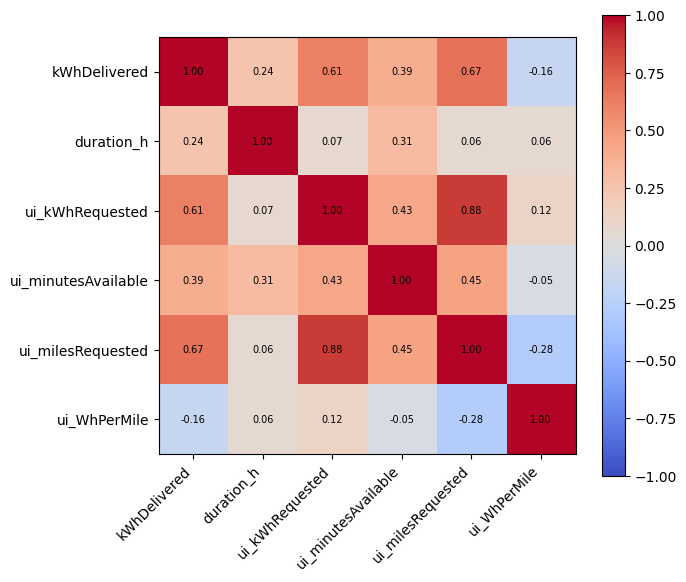

In [12]:
cols = [c for c in ["kWhDelivered", "duration_h", "ui_kWhRequested",
                    "ui_minutesAvailable", "ui_milesRequested", "ui_WhPerMile"] if c in clean_df]
corr = clean_df[cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/correlation.png", dpi=150); plt.show()

## 7. Build the target: occupancy per site

Occupancy(t) is the number of cars plugged in at time t. Arrivals are rounded **down** to the grid and departures **up**, so a car counts as present in every slot it touches. Then `cumsum(arrivals - departures)` gives the count.

In [40]:
def occupancy_series(d, freq=FREQ):
    start = d["connectionTime"].min().floor(freq)
    end = d["disconnectTime"].max().ceil(freq)
    grid = pd.date_range(start, end, freq=freq)
    arr = d["connectionTime"].dt.floor(freq).value_counts()
    dep = d["disconnectTime"].dt.ceil(freq).value_counts()
    delta = arr.reindex(grid, fill_value=0) - dep.reindex(grid, fill_value=0)
    return delta.cumsum().rename("occupancy")

occ = {site: occupancy_series(g) for site, g in clean_df.groupby("site")}
{s: (o.index.min(), o.index.max(), int(o.max())) for s, o in occ.items()}

{'caltech': (Timestamp('2019-01-01 05:15:00+0000', tz='UTC'),
  Timestamp('2021-09-14 03:15:00+0000', tz='UTC'),
  38),
 'jpl': (Timestamp('2019-01-02 01:00:00+0000', tz='UTC'),
  Timestamp('2021-09-14 15:00:00+0000', tz='UTC'),
  56)}

## 8. Occupancy plots

- Mean weekday occupancy by time of day: the typical weekday curve (Mon to Fri averaged per time of day)
- Mean occupancy by day of week
- Monthly mean occupancy: shows drift (COVID, EV adoption, capacity changes)

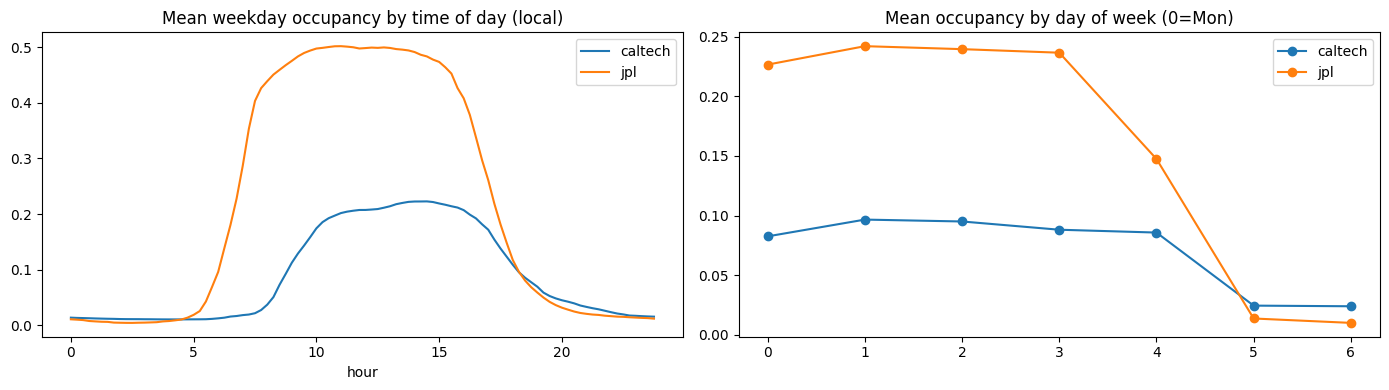

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for site, s in occ.items():
    loc = s.tz_convert(LOCAL_TZ)
    wd = loc[loc.index.dayofweek < 5]
    wd.groupby(wd.index.hour + wd.index.minute / 60).mean().plot(ax=ax[0], label=site)
    loc.groupby(loc.index.dayofweek).mean().plot(ax=ax[1], marker="o", label=site)
ax[0].set_title("Mean weekday occupancy by time of day (local)"); ax[0].set_xlabel("hour"); ax[0].legend()
ax[1].set_title("Mean occupancy by day of week (0=Mon)"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/occupancy_profiles.png", dpi=150); plt.show()

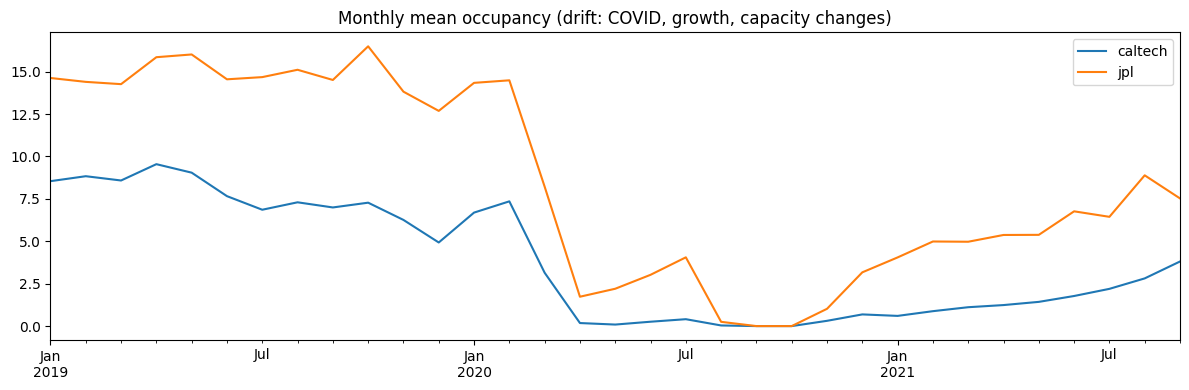

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
for site, s in occ.items():
    s.resample("MS").mean().plot(ax=ax, label=site)
ax.set_title("Monthly mean occupancy (drift: COVID, growth, capacity changes)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/occupancy_drift.png", dpi=150); plt.show()

## 9. Feature engineering

Target `y` is the occupancy `HORIZON_STEPS` steps ahead. Every feature uses information available at time t only (no leakage).

In [52]:
H = HORIZON_STEPS 

def build_features(occ, horizon=H):
    # local time of the value we are predicting (t + horizon)
    tgt = (occ.index + pd.Timedelta(minutes=15 * horizon)).tz_convert(LOCAL_TZ)

    X = pd.DataFrame({"y": occ.shift(-horizon)})        # target: occupancy at t+H
    X["occ_now"] = occ                                  # how full is it now
    X["occ_yesterday"] = occ.shift(96 - horizon)        # occupancy at t+H, one day earlier
    X["occ_last_week"] = occ.shift(672 - horizon)       # occupancy at t+H, one week earlier
    X["hour"] = tgt.hour + tgt.minute / 60              # time of day being predicted
    X["dow"] = tgt.dayofweek                            # weekday being predicted

    X["hour_sin"] = np.sin(2 * np.pi * X["hour"] / 24)
    X["hour_cos"] = np.cos(2 * np.pi * X["hour"] / 24)

    X["dow_sin"] = np.sin(2 * np.pi * X["dow"] / 7)
    X["dow_cos"] = np.cos(2 * np.pi * X["dow"] / 7)

    X = X.drop(columns=["hour", "dow"])
    
    try:
        import holidays
        hol = holidays.US(state="CA")
        X["is_holiday"] = [int(d in hol) for d in tgt.date]
    except ImportError:
        X["is_holiday"] = 0                        
    return X

parts = []
for site, g in clean_df.groupby("site"):
    f = build_features(occ[site])
    f["site"] = site
    parts.append(f)
features = pd.concat(parts).dropna()
print(features.shape)
features.head()

(188114, 10)


,y,occ_now,occ_yesterday,occ_last_week,hour_sin,hour_cos,dow_sin,dow_cos,is_holiday,site
2019-01-08 04:15:00+00:00,2.0,3,2.0,1.0,-0.659346,0.751840,0.0,1.0,0,caltech
2019-01-08 04:30:00+00:00,1.0,3,2.0,1.0,-0.608761,0.793353,0.0,1.0,0,caltech
2019-01-08 04:45:00+00:00,1.0,2,2.0,1.0,-0.555570,0.831470,0.0,1.0,0,caltech
2019-01-08 05:00:00+00:00,1.0,2,2.0,1.0,-0.500000,0.866025,0.0,1.0,0,caltech
2019-01-08 05:15:00+00:00,1.0,2,2.0,0.0,-0.442289,0.896873,0.0,1.0,0,caltech


## 10. Save outputs

In [49]:
try:
    features.to_parquet(f"{OUT_DIR}/occupancy_features.parquet")
    print("saved parquet")

except ImportError:
    features.to_csv(f"{OUT_DIR}/occupancy_features.csv")
    print("pyarrow not installed: saved CSV instead")

saved parquet
